# BÀI TẬP LỚN HỌC MÁY - BÁO CÁO MILESTONE 1
## 01. Phân Tích Dữ Liệu Khám Phá (EDA) & Thiết Kế Pipeline Tiền Xử Lý Chống Data Leakage
---
- **Bộ dữ liệu:** Framingham Heart Study (`data/framingham.csv`)
- **Mục tiêu:** Sàng lọc & Dự báo nguy cơ mắc bệnh tim mạch vành trong 10 năm (`TenYearCHD`)
- **Thành viên phụ trách:** Thành viên 1 (Nhóm trưởng) & Thành viên 3
- **Mốc chấm:** Milestone 1 (Checkpoint Buổi 4) - Bám sát Nhiệm vụ STT 1, 3, 4, 5 trong Bảng Phân Công

In [58]:
# 1. Import các thư viện phân tích và hệ thống
import os
import sys
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thêm thư mục gốc vào sys.path để import trực tiếp từ src
sys.path.append(os.path.abspath('..'))
from src.features import (
    create_features,
    get_preprocessor_pipeline,
    load_and_split_data,
    NUMERIC_FEATURES,
    CATEGORICAL_FEATURES,
    TARGET_COLUMN
)

# Cấu hình giao diện biểu đồ
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', None)
print('Imports và cấu hình thành công!')

Imports và cấu hình thành công!


## 1. Tải Dữ Liệu & Kiểm Tra Cấu Trúc Tổng Quát
Sử dụng đường dẫn tương đối chuẩn `../data/framingham.csv` theo quy ước của nhóm.

In [ ]:
df = pd.read_csv('../data/framingham.csv')
print(f'Kích thước bộ dữ liệu ban đầu: {df.shape[0]} dòng x {df.shape[1]} cột')
df.head()

Kích thước bộ dữ liệu ban đầu: 4240 dòng x 16 cột


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


: 

: 

In [ ]:
# Thống kê mô tả các biến số
df.describe().T

,count,mean,std,min,25%,50%,75%,max
male,4240.0,0.429245,0.495027,0.00,0.00,0.0,1.00,1.0
age,4240.0,49.580189,8.572942,32.00,42.00,49.0,56.00,70.0
education,4135.0,1.979444,1.019791,1.00,1.00,2.0,3.00,4.0
currentSmoker,4240.0,0.494104,0.500024,0.00,0.00,0.0,1.00,1.0
cigsPerDay,4211.0,9.005937,11.922462,0.00,0.00,0.0,20.00,70.0
BPMeds,4187.0,0.029615,0.169544,0.00,0.00,0.0,0.00,1.0
prevalentStroke,4240.0,0.005896,0.076569,0.00,0.00,0.0,0.00,1.0
prevalentHyp,4240.0,0.310613,0.462799,0.00,0.00,0.0,1.00,1.0
diabetes,4240.0,0.025708,0.158280,0.00,0.00,0.0,0.00,1.0
totChol,4190.0,236.699523,44.591284,107.00,206.00,234.0,263.00,696.0


: 

: 

## 2. Kiểm Tra Dữ Liệu Thiếu (Missing Values)
Phát hiện các cột có dữ liệu thiếu để thiết kế chiến lược điền khuyết (Imputation) phù hợp.

In [ ]:
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Số lượng khuyết': missing, 'Tỷ lệ (%)': missing_pct})
missing_df = missing_df[missing_df['Số lượng khuyết'] > 0].sort_values('Số lượng khuyết', ascending=False)

print(f'Tổng số giá trị bị khuyết: {df.isnull().sum().sum()}')
print(f'Số lượng cột bị khuyết: {len(missing_df)} / {df.shape[1]}')
missing_df

Tổng số giá trị bị khuyết: 645
Số lượng cột bị khuyết: 7 / 16


,Số lượng khuyết,Tỷ lệ (%)
glucose,388,9.15
education,105,2.48
BPMeds,53,1.25
totChol,50,1.18
cigsPerDay,29,0.68
BMI,19,0.45
heartRate,1,0.02


: 

: 

## 3. Trực Quan Hóa Dữ Liệu Khám Phá (EDA)
Phân tích phân phối lớp mục tiêu `TenYearCHD`, các biến số lâm sàng và mối tương quan giữa các đặc trưng.

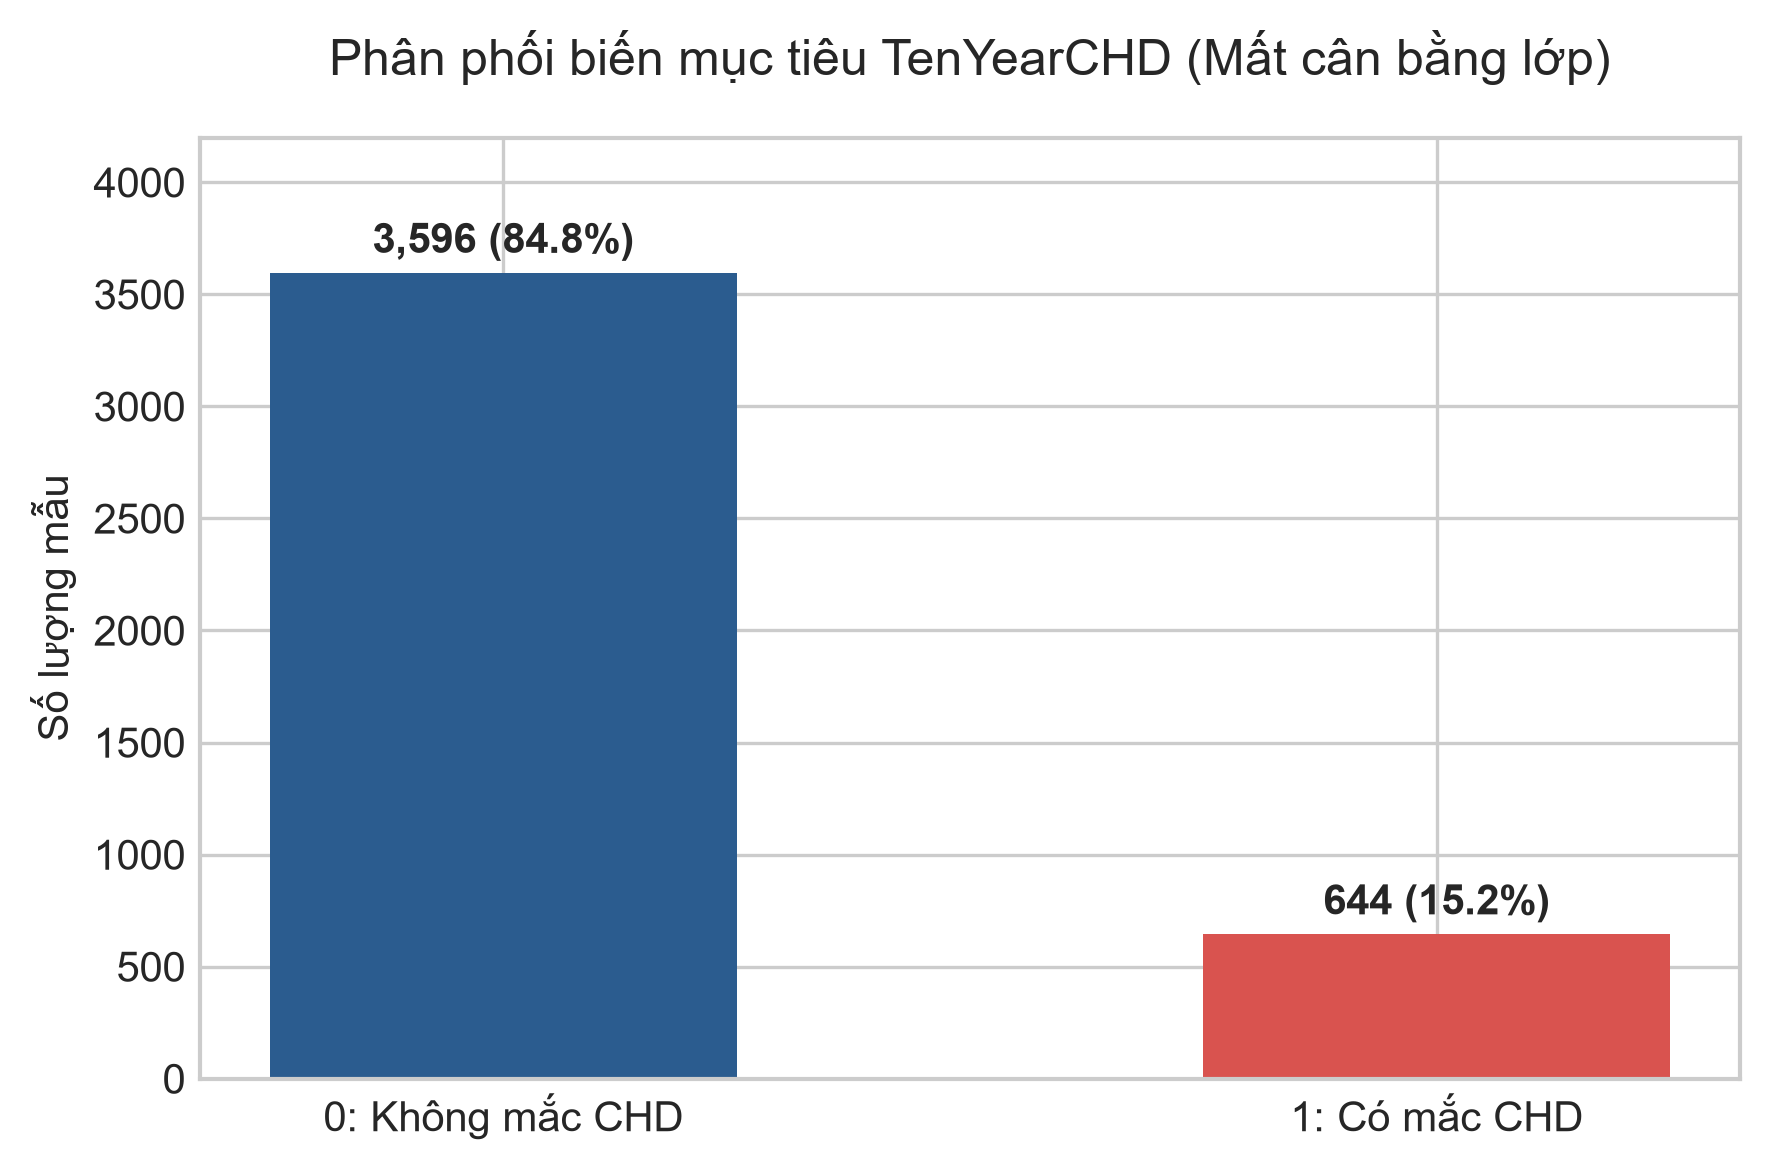

: 

: 

In [ ]:
# 3.1. Phân phối biến mục tiêu TenYearCHD (Mất cân bằng dữ liệu)
fig, ax = plt.subplots(figsize=(6, 4), dpi=300)
counts = df[TARGET_COLUMN].value_counts()
colors = ['#2b5c8f', '#d9534f']
bars = ax.bar(['0: Không mắc CHD', '1: Có mắc CHD'], counts.values, color=colors, width=0.5)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 50, f'{yval:,} ({yval/len(df):.1%})', 
            ha='center', va='bottom', fontweight='bold')

ax.set_title('Phân phối biến mục tiêu TenYearCHD (Mất cân bằng lớp)', fontsize=12, pad=15)
ax.set_ylabel('Số lượng mẫu')
ax.set_ylim(0, 4200)
plt.tight_layout()
plt.show()

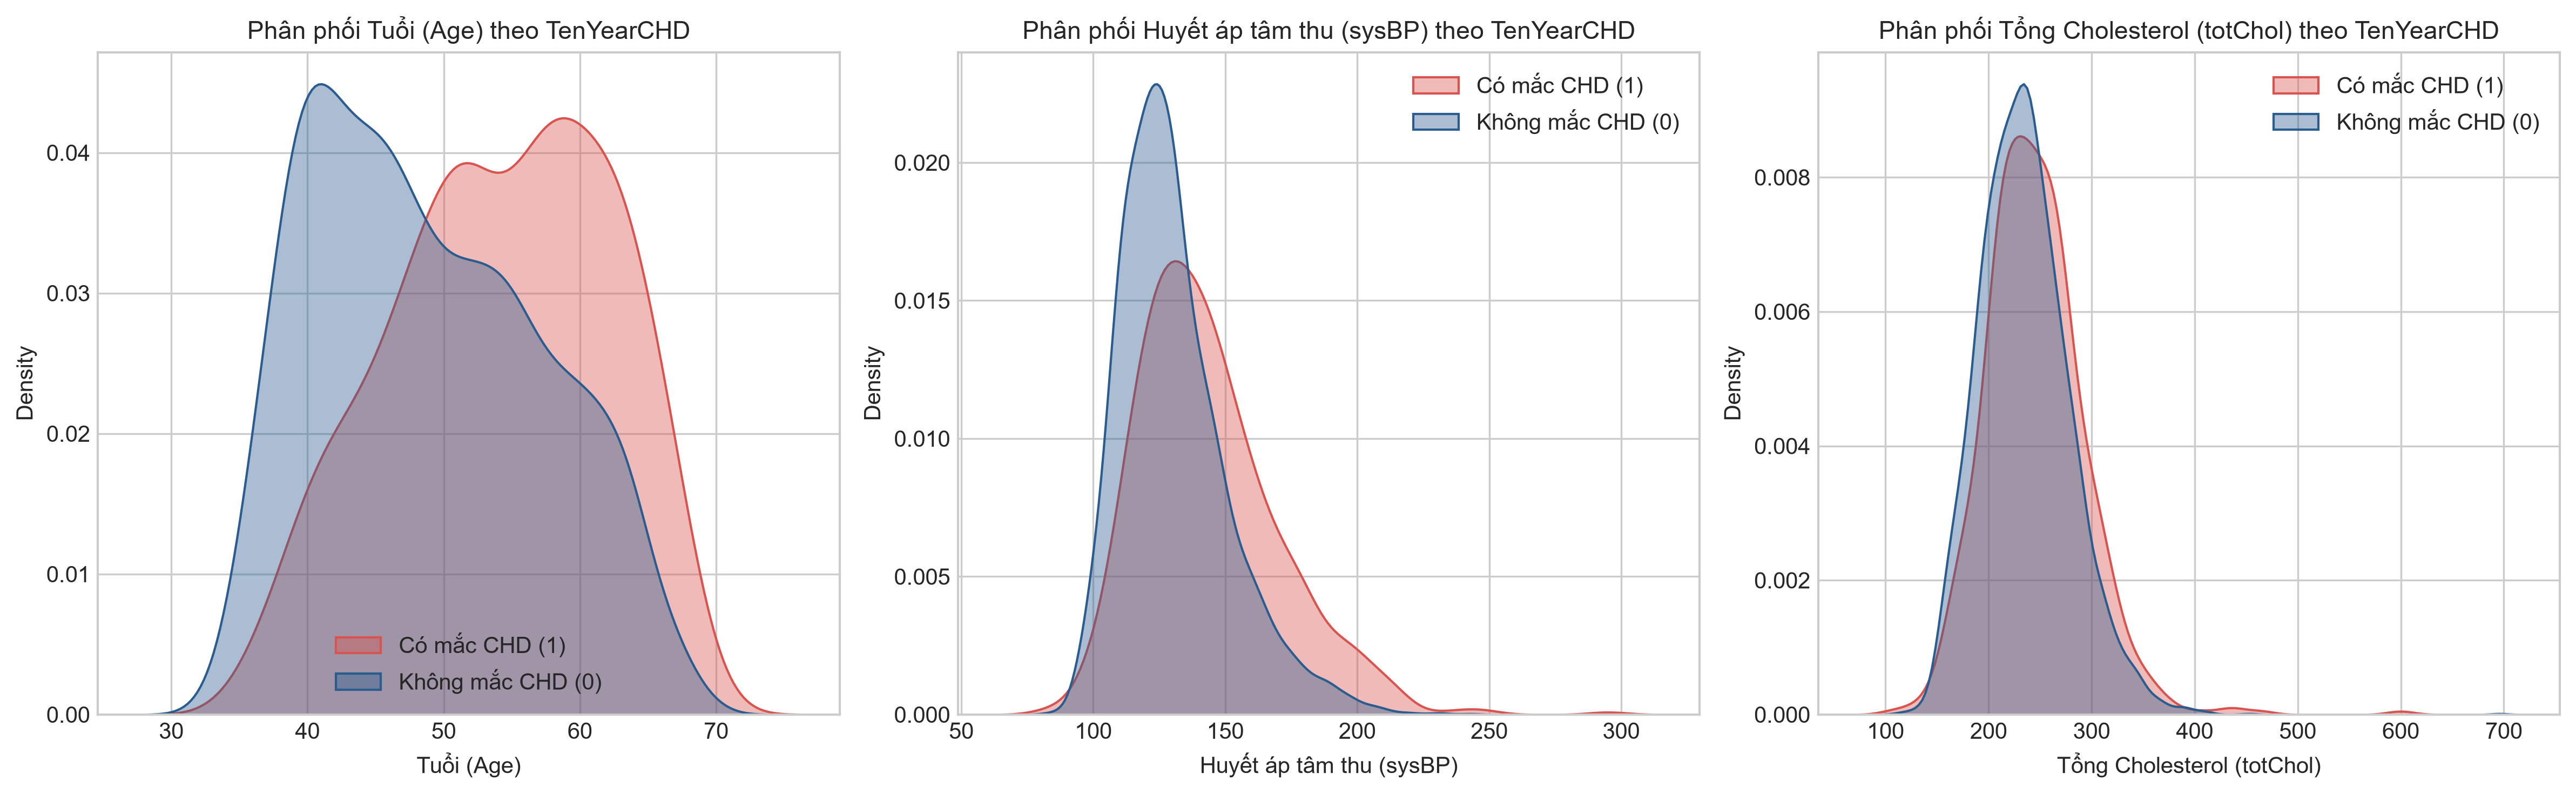

: 

: 

In [ ]:
# 3.2. Phân phối tuổi, huyết áp, cholesterol theo nhóm mắc bệnh
fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=300)
features_plot = [('age', 'Tuổi (Age)'), ('sysBP', 'Huyết áp tâm thu (sysBP)'), ('totChol', 'Tổng Cholesterol (totChol)')]

for i, (col, label) in enumerate(features_plot):
    sns.kdeplot(data=df, x=col, hue=TARGET_COLUMN, common_norm=False, 
                palette=['#2b5c8f', '#d9534f'], fill=True, alpha=0.4, ax=axes[i])
    axes[i].set_title(f'Phân phối {label} theo TenYearCHD', fontsize=11)
    axes[i].set_xlabel(label)
    axes[i].legend(['Có mắc CHD (1)', 'Không mắc CHD (0)'])

plt.tight_layout()
plt.show()

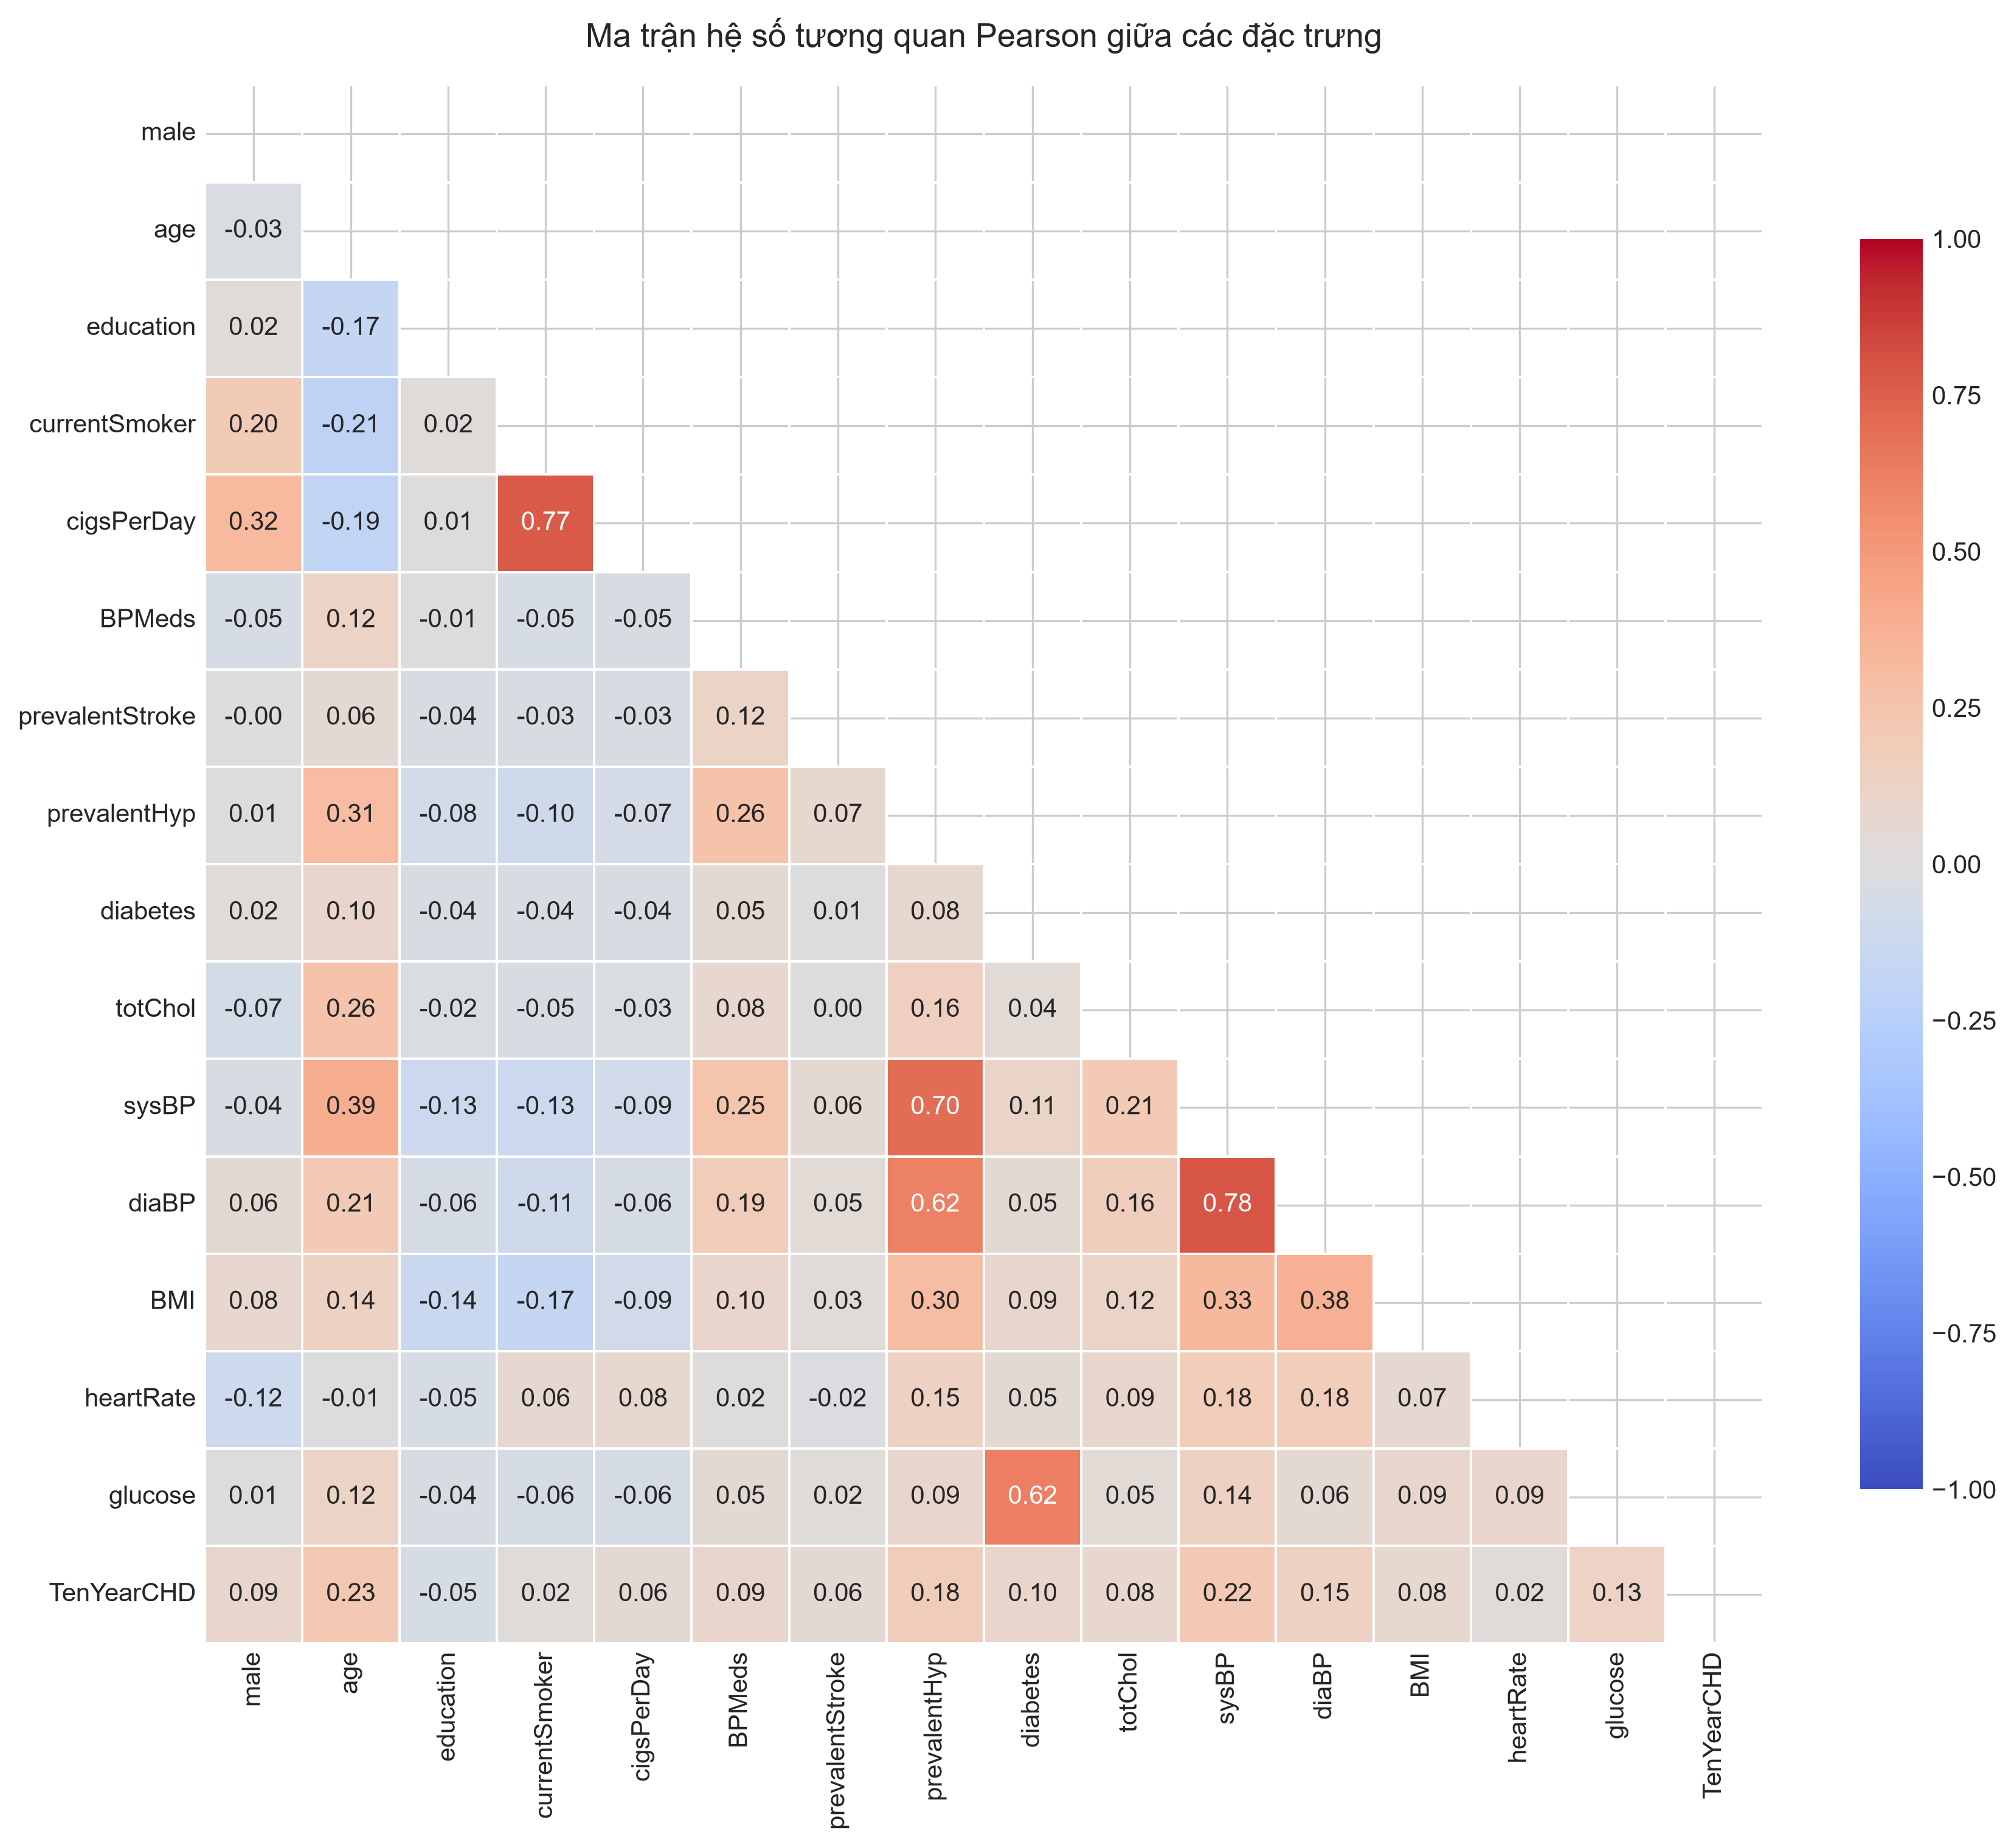

: 

: 

In [ ]:
# 3.3. Ma trận tương quan (Correlation Matrix Heatmap)
fig, ax = plt.subplots(figsize=(12, 10), dpi=300)
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, 
            center=0, square=True, linewidths=.5, cbar_kws={'shrink': .8}, ax=ax)
ax.set_title('Ma trận hệ số tương quan Pearson giữa các đặc trưng', fontsize=13, pad=15)
plt.tight_layout()
plt.show()

> **Nhận xét quan trọng:**
> 1. **Tương quan mạnh giữa huyết áp tâm thu (`sysBP`) và tâm trương (`diaBP`)**: Hệ số tương quan $r = 0.78$. Cả hai phản ánh tình trạng áp lực lòng mạch. Do đó, việc kết hợp thành các chỉ số y khoa như **Áp lực mạch (Pulse Pressure)** và **Huyết áp trung bình (MAP)** là có cơ sở khoa học vững chắc.
> 2. **Tương quan giữa `currentSmoker` và `cigsPerDay`** ($r = 0.77$): Người hút thuốc có nguy cơ cao hơn khi tuổi tác tăng lên. Đặc trưng tích hợp `age_cigs_interaction` sẽ nắm bắt hiệu ứng tương tác này.

---
## 4. Kỹ Thuật Tạo Đặc Trưng Mới (Feature Engineering - STT 5)
Dựa trên kiến thức chuyên môn tim mạch và phân tích EDA ở trên, ta tạo 3 đặc trưng mới:
1. **`pulse_pressure` (Áp lực mạch):**
   $$\text{pulse\_pressure} = \text{sysBP} - \text{diaBP}$$
   *Ý nghĩa y học:* Độ chênh lệch phản ánh độ cứng thành động mạch. Áp lực mạch cao (> 60 mmHg) là yếu tố độc lập dự báo xơ vữa động mạch và đột quỵ.
2. **`MAP` (Mean Arterial Pressure - Huyết áp động mạch trung bình):**
   $$\text{MAP} = \text{diaBP} + \frac{\text{sysBP} - \text{diaBP}}{3}$$
   *Ý nghĩa y học:* Áp lực tưới máu thực tế liên tục đến các cơ quan quan trọng, toàn diện hơn huyết áp đơn lẻ.
3. **`age_cigs_interaction` (Tương tác Tuổi x Lượng thuốc lá):**
   $$\text{age\_cigs\_interaction} = \text{age} \times \text{cigsPerDay}$$
   *Ý nghĩa y học:* Mức độ phơi nhiễm độc chất khói thuốc theo thời gian tích lũy theo số năm tuổi.

In [ ]:
# Thử nghiệm hàm create_features từ module src/features.py
df_featured = create_features(df)
print('3 đặc trưng mới đã được bổ sung vào DataFrame:')
df_featured[['sysBP', 'diaBP', 'pulse_pressure', 'MAP', 'age', 'cigsPerDay', 'age_cigs_interaction']].head()

3 đặc trưng mới đã được bổ sung vào DataFrame:


,sysBP,diaBP,pulse_pressure,MAP,age,cigsPerDay,age_cigs_interaction
0,106.0,70.0,36.0,82.000000,39,0.0,0.0
1,121.0,81.0,40.0,94.333333,46,0.0,0.0
2,127.5,80.0,47.5,95.833333,48,20.0,960.0
3,150.0,95.0,55.0,113.333333,61,30.0,1830.0
4,130.0,84.0,46.0,99.333333,46,23.0,1058.0


: 

: 

---
## 5. Chia Tập Dữ Liệu Train / Test (Tuân Thủ Tuyệt Đối Quy Ước 1 & 2)
> ⚠️ **LƯU Ý BẮT BUỘC ĐỂ KHÔNG BỊ TRỪ ĐIỂM (Data Leakage):**
> - BẮT BUỘC thực hiện chia tập Train (80%) và Test (20%) bằng `train_test_split` trước khi thực hiện bất kỳ phép `fit` nào của Imputer hoặc Scaler.
> - Dùng `stratify=y` và `random_state=42` để cố định dữ liệu và bảo toàn tỷ lệ nhãn cho cả 3 máy.

In [ ]:
# Gọi hàm load_and_split_data chuẩn từ module src/features.py
X_train, X_test, y_train, y_test = load_and_split_data(
    data_path='../data/framingham.csv',
    test_size=0.2,
    random_state=42
)

print(f'Kích thước X_train: {X_train.shape} | y_train: {y_train.shape}')
print(f'Kích thước X_test:  {X_test.shape}  | y_test:  {y_test.shape}')
print(f'Tỷ lệ nhãn dương (TenYearCHD=1) trên Train: {y_train.mean():.4f}')
print(f'Tỷ lệ nhãn dương (TenYearCHD=1) trên Test:  {y_test.mean():.4f}')

Kích thước X_train: (3392, 15) | y_train: (3392,)
Kích thước X_test:  (848, 15)  | y_test:  (848,)
Tỷ lệ nhãn dương (TenYearCHD=1) trên Train: 0.1518
Tỷ lệ nhãn dương (TenYearCHD=1) trên Test:  0.1521


: 

: 

---
## 6. Đóng Gói Bộ Tiền Xử Lý Pipeline (ColumnTransformer) Chống Rò Rỉ Dữ Liệu
Toàn bộ quy trình tiền xử lý được đóng gói trong một `Pipeline` duy nhất gồm:
1. **`HeartDiseaseFeatureEngineer`:** Tự động tính toán 3 đặc trưng mới trên dữ liệu.
2. **`ColumnTransformer`:**
   - **11 Đặc trưng số:** `SimpleImputer(strategy='median')` -> `StandardScaler()`
   - **7 Đặc trưng phân loại:** `SimpleImputer(strategy='most_frequent')`

**Cơ chế chống Data Leakage:**
- `pipeline.fit(X_train)`: Chỉ học Median và Mean/Std từ `X_train`.
- `pipeline.transform(X_test)`: Dùng nguyên các thông số học được từ `X_train` áp dụng lên `X_test`.

In [ ]:
# Khởi tạo Pipeline tiền xử lý hoàn chỉnh từ src/features.py
preprocessor_pipeline = get_preprocessor_pipeline()
print('Pipeline đã khởi tạo thành công:')
preprocessor_pipeline

Pipeline đã khởi tạo thành công:


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_engineering', ...), ('preprocessor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, def

: 

: 

In [ ]:
# FIT CHỈ TRÊN TẬP TRAIN (Chống rò rỉ dữ liệu)
preprocessor_pipeline.fit(X_train, y_train)

# Transform trên cả Train và Test độc lập
X_train_processed = preprocessor_pipeline.transform(X_train)
X_test_processed = preprocessor_pipeline.transform(X_test)

print(f'X_train sau tiền xử lý: {X_train_processed.shape}')
print(f'X_test sau tiền xử lý:  {X_test_processed.shape}')
print(f'Số giá trị NaN còn lại trong X_train: {np.isnan(X_train_processed).sum()}')
print(f'Số giá trị NaN còn lại trong X_test:  {np.isnan(X_test_processed).sum()}')

X_train sau tiền xử lý: (3392, 18)
X_test sau tiền xử lý:  (848, 18)
Số giá trị NaN còn lại trong X_train: 0
Số giá trị NaN còn lại trong X_test:  0


: 

: 

## 7. Xuất & Lưu Pipeline Hoàn Chỉnh Cho Thành Viên 2 (Phụ Trách Mô Hình)
Lưu `preprocessor_pipeline` đã fit vào thư mục `models/` để Thành viên 2 (Mô hình Baseline & Multi-Model) lắp trực tiếp vào mô hình huấn luyện.

In [ ]:
import joblib

os.makedirs('../models', exist_ok=True)
pipeline_save_path = '../models/preprocessor_pipeline.joblib'
joblib.dump(preprocessor_pipeline, pipeline_save_path)
print(f'Đã lưu thành công bộ tiền xử lý Pipeline tại: {pipeline_save_path}')
print('Hoàn tất toàn bộ yêu cầu của STT 5 (Mốc 1 Checkpoint 1)!')

Đã lưu thành công bộ tiền xử lý Pipeline tại: ../models/preprocessor_pipeline.joblib
Hoàn tất toàn bộ yêu cầu của STT 5 (Mốc 1 Checkpoint 1)!


: 

: 

---
# BASELINE MODEL – LOGISTIC REGRESSION (TV2)
## Mô hình Baseline Logistic Regression cho dự báo TenYearCHD
**Thành viên phụ trách:** Thành viên 2
**Mốc chấm:** Milestone 1 (Checkpoint 1 - Lesson 4)

Mục tiêu: Xây dựng mô hình baseline Logistic Regression với:
- Pipeline tích hợp tiền xử lý TV1 + Logistic Regression
- Chia Train/Test 80/20 (stratify, random_state=42) - **Tái sử dụng từ TV1**
- Stratified 5-Fold Cross-Validation trên tập Train
- Đánh giá trên tập Test holdout
- Trực quan hóa: Confusion Matrix & ROC Curve

In [ ]:
# 1. Import thư viện cho Baseline Model
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, ConfusionMatrixDisplay
)

# Tái sử dụng các biến đã định nghĩa từ TV1
# X_train, X_test, y_train, y_test đã được tạo ở phần 5
# get_preprocessor_pipeline() từ src.features

print('Imports baseline model thành công!')
print(f'X_train shape: {X_train.shape}')
print(f'X_test shape: {X_test.shape}')
print(f'y_train distribution: {y_train.value_counts().to_dict()}')
print(f'y_test distribution: {y_test.value_counts().to_dict()}')

Imports baseline model thành công!
X_train shape: (3392, 15)
X_test shape: (848, 15)
y_train distribution: {0: 2877, 1: 515}
y_test distribution: {0: 719, 1: 129}


: 

: 

## 2. Xây Dựng Pipeline Hoàn Chỉnh: Tiền Xử Lý TV1 + Logistic Regression
Pipeline kết hợp:
1. **Feature Engineering** (TV1): Tạo pulse_pressure, MAP, age_cigs_interaction
2. **ColumnTransformer** (TV1): Imputer + Scaler cho numeric, Imputer cho categorical
3. **Logistic Regression** (TV2): `class_weight='balanced'`, `random_state=42`, `max_iter=1000`

**Quan trọng:** Pipeline **chưa fit** - sẽ được fit bên trong cross-validation và sau đó fit trên toàn bộ X_train. Điều này đảm bảo **không có Data Leakage**.

In [ ]:
# 2.1. Khởi tạo Logistic Regression với cấu hình yêu cầu
lr_model = LogisticRegression(
    class_weight='balanced',
    random_state=42,
    max_iter=1000
)

# 2.2. Lấy pipeline tiền xử lý CHƯA FIT từ TV1
preprocessor = get_preprocessor_pipeline()

# 2.3. Xây dựng Pipeline hoàn chỉnh: Preprocessing + Model
baseline_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', lr_model)
])

print('Baseline Pipeline đã được xây dựng:')
baseline_pipeline

Baseline Pipeline đã được xây dựng:


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_engineering', ...), ('preprocessor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its par

: 

: 

## 3. Stratified 5-Fold Cross-Validation trên Tập Train
Sử dụng `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` và `cross_validate` với các metric:
- ROC-AUC (`roc_auc`)
- Recall (`recall`)
- F1-score (`f1`)
- Precision (`precision`)
- Accuracy (`accuracy`)

**Lưu ý:** Cross-validation được thực hiện **CHỈ TRÊN TẬP TRAIN** (X_train, y_train). Tập Test hoàn toàn không được chạm đến.

In [ ]:
# 3.1. Cấu hình Stratified K-Fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 3.2. Định nghĩa các metric scoring
scoring = {
    'roc_auc': 'roc_auc',
    'recall': 'recall',
    'f1': 'f1',
    'precision': 'precision',
    'accuracy': 'accuracy'
}

# 3.3. Thực hiện Cross-Validation trên tập Train
print('Đang thực hiện Stratified 5-Fold Cross-Validation...')
cv_results = cross_validate(
    baseline_pipeline,
    X_train, y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1
)

print('Hoàn tất Cross-Validation!')

# 3.4. Hiển thị kết quả chi tiết từng fold
cv_df = pd.DataFrame({
    'Fold': range(1, 6),
    'ROC-AUC': cv_results['test_roc_auc'],
    'Recall': cv_results['test_recall'],
    'F1-Score': cv_results['test_f1'],
    'Precision': cv_results['test_precision'],
    'Accuracy': cv_results['test_accuracy']
})
print('\n--- Kết quả Cross-Validation từng Fold ---')
print(cv_df.to_string(index=False))

# 3.5. Tổng hợp Mean ± Std
print('\n--- Tổng hợp Cross-Validation (Mean ± Std) ---')
for metric in ['roc_auc', 'recall', 'f1', 'precision', 'accuracy']:
    scores = cv_results[f'test_{metric}']
    print(f'{metric.upper():10s}: {scores.mean():.4f} ± {scores.std():.4f}')

Đang thực hiện Stratified 5-Fold Cross-Validation...
Hoàn tất Cross-Validation!

--- Kết quả Cross-Validation từng Fold ---
 Fold  ROC-AUC   Recall  F1-Score  Precision  Accuracy
    1 0.703698 0.640777  0.360656   0.250951  0.655376
    2 0.694798 0.650485  0.352632   0.241877  0.637703
    3 0.741680 0.718447  0.393617   0.271062  0.663717
    4 0.779924 0.737864  0.443149   0.316667  0.718289
    5 0.733153 0.660194  0.396501   0.283333  0.694690

--- Tổng hợp Cross-Validation (Mean ± Std) ---
ROC_AUC   : 0.7307 ± 0.0302
RECALL    : 0.6816 ± 0.0390
F1        : 0.3893 ± 0.0320
PRECISION : 0.2728 ± 0.0264
ACCURACY  : 0.6740 ± 0.0288


: 

: 

## 4. Huấn Luyện Mô Hình Cuối Cùng Trên Toàn Bộ Tập Train
Sau khi đánh giá CV, fit pipeline trên **toàn bộ X_train** để tạo mô hình cuối cùng cho dự đoán trên Test.

In [ ]:
# 4.1. Fit pipeline trên toàn bộ tập Train
print('Đang fit mô hình Baseline trên toàn bộ X_train...')
baseline_pipeline.fit(X_train, y_train)
print('Fit hoàn tất!')

# 4.2. Dự đoán trên tập Test holdout
y_pred = baseline_pipeline.predict(X_test)
y_prob = baseline_pipeline.predict_proba(X_test)[:, 1]

print(f'\nSố lượng dự đoán dương tính (TenYearCHD=1): {y_pred.sum()} / {len(y_pred)} ({y_pred.mean():.2%})')
print(f'Số lượng thực tế dương tính: {y_test.sum()} / {len(y_test)} ({y_test.mean():.2%})')

Đang fit mô hình Baseline trên toàn bộ X_train...
Fit hoàn tất!

Số lượng dự đoán dương tính (TenYearCHD=1): 304 / 848 (35.85%)
Số lượng thực tế dương tính: 129 / 848 (15.21%)


: 

: 

## 5. Đánh Giá Mô Hình Trên Tập Test Holdout
Tính toán các metric trên tập Test chưa từng được sử dụng trong huấn luyện hay CV.

In [ ]:
# 5.1. Tính các metric trên Test set
test_metrics = {
    'ROC-AUC': roc_auc_score(y_test, y_prob),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Accuracy': accuracy_score(y_test, y_pred)
}

# 5.2. Bảng so sánh Cross-Validation vs Test Set
cv_means = {k: np.mean(v) for k, v in cv_results.items() if k.startswith('test_')}
cv_stds = {k: np.std(v) for k, v in cv_results.items() if k.startswith('test_')}

comparison_df = pd.DataFrame({
    'Metric': ['ROC-AUC', 'Recall', 'F1-Score', 'Precision', 'Accuracy'],
    'CV Mean': [cv_means['test_roc_auc'], cv_means['test_recall'], cv_means['test_f1'], cv_means['test_precision'], cv_means['test_accuracy']],
    'CV Std': [cv_stds['test_roc_auc'], cv_stds['test_recall'], cv_stds['test_f1'], cv_stds['test_precision'], cv_stds['test_accuracy']],
    'Test Set': [test_metrics['ROC-AUC'], test_metrics['Recall'], test_metrics['F1-Score'], test_metrics['Precision'], test_metrics['Accuracy']]
})

print('=== BẢNG SO SÁNH KẾT QUẢ CROSS-VALIDATION vs TEST SET ===')
print(comparison_df.to_string(index=False))

# 5.3. Classification Report chi tiết
print('\n=== CLASSIFICATION REPORT (Test Set) ===')
print(classification_report(y_test, y_pred, target_names=['Không mắc CHD (0)', 'Có mắc CHD (1)']))

=== BẢNG SO SÁNH KẾT QUẢ CROSS-VALIDATION vs TEST SET ===
   Metric  CV Mean   CV Std  Test Set
  ROC-AUC 0.730651 0.030224  0.700165
   Recall 0.681553 0.039029  0.596899
 F1-Score 0.389311 0.032048  0.355658
Precision 0.272778 0.026351  0.253289
 Accuracy 0.673955 0.028843  0.670991

=== CLASSIFICATION REPORT (Test Set) ===
                   precision    recall  f1-score   support

Không mắc CHD (0)       0.90      0.68      0.78       719
   Có mắc CHD (1)       0.25      0.60      0.36       129

         accuracy                           0.67       848
        macro avg       0.58      0.64      0.57       848
     weighted avg       0.81      0.67      0.71       848



: 

: 

## 6. Confusion Matrix (Ma Trận Nhầm Lẫn)
Trực quan hóa hiệu suất phân loại trên tập Test:
- **TN (True Negative):** Dự đoán 0, Thực tế 0 - Dự đoán đúng không mắc bệnh
- **FP (False Positive):** Dự đoán 1, Thực tế 0 - Dự đoán sai có mắc bệnh (Type I Error)
- **FN (False Negative):** Dự đoán 0, Thực tế 1 - Dự đoán sai không mắc bệnh (Type II Error) - **Nguy hiểm trong y tế**
- **TP (True Positive):** Dự đoán 1, Thực tế 1 - Dự đoán đúng có mắc bệnh

True Negative (TN):  492
False Positive (FP): 227
False Negative (FN): 52
True Positive (TP):  77
Đã lưu Confusion Matrix tại: ../notebooks/figures/baseline_confusion_matrix.png


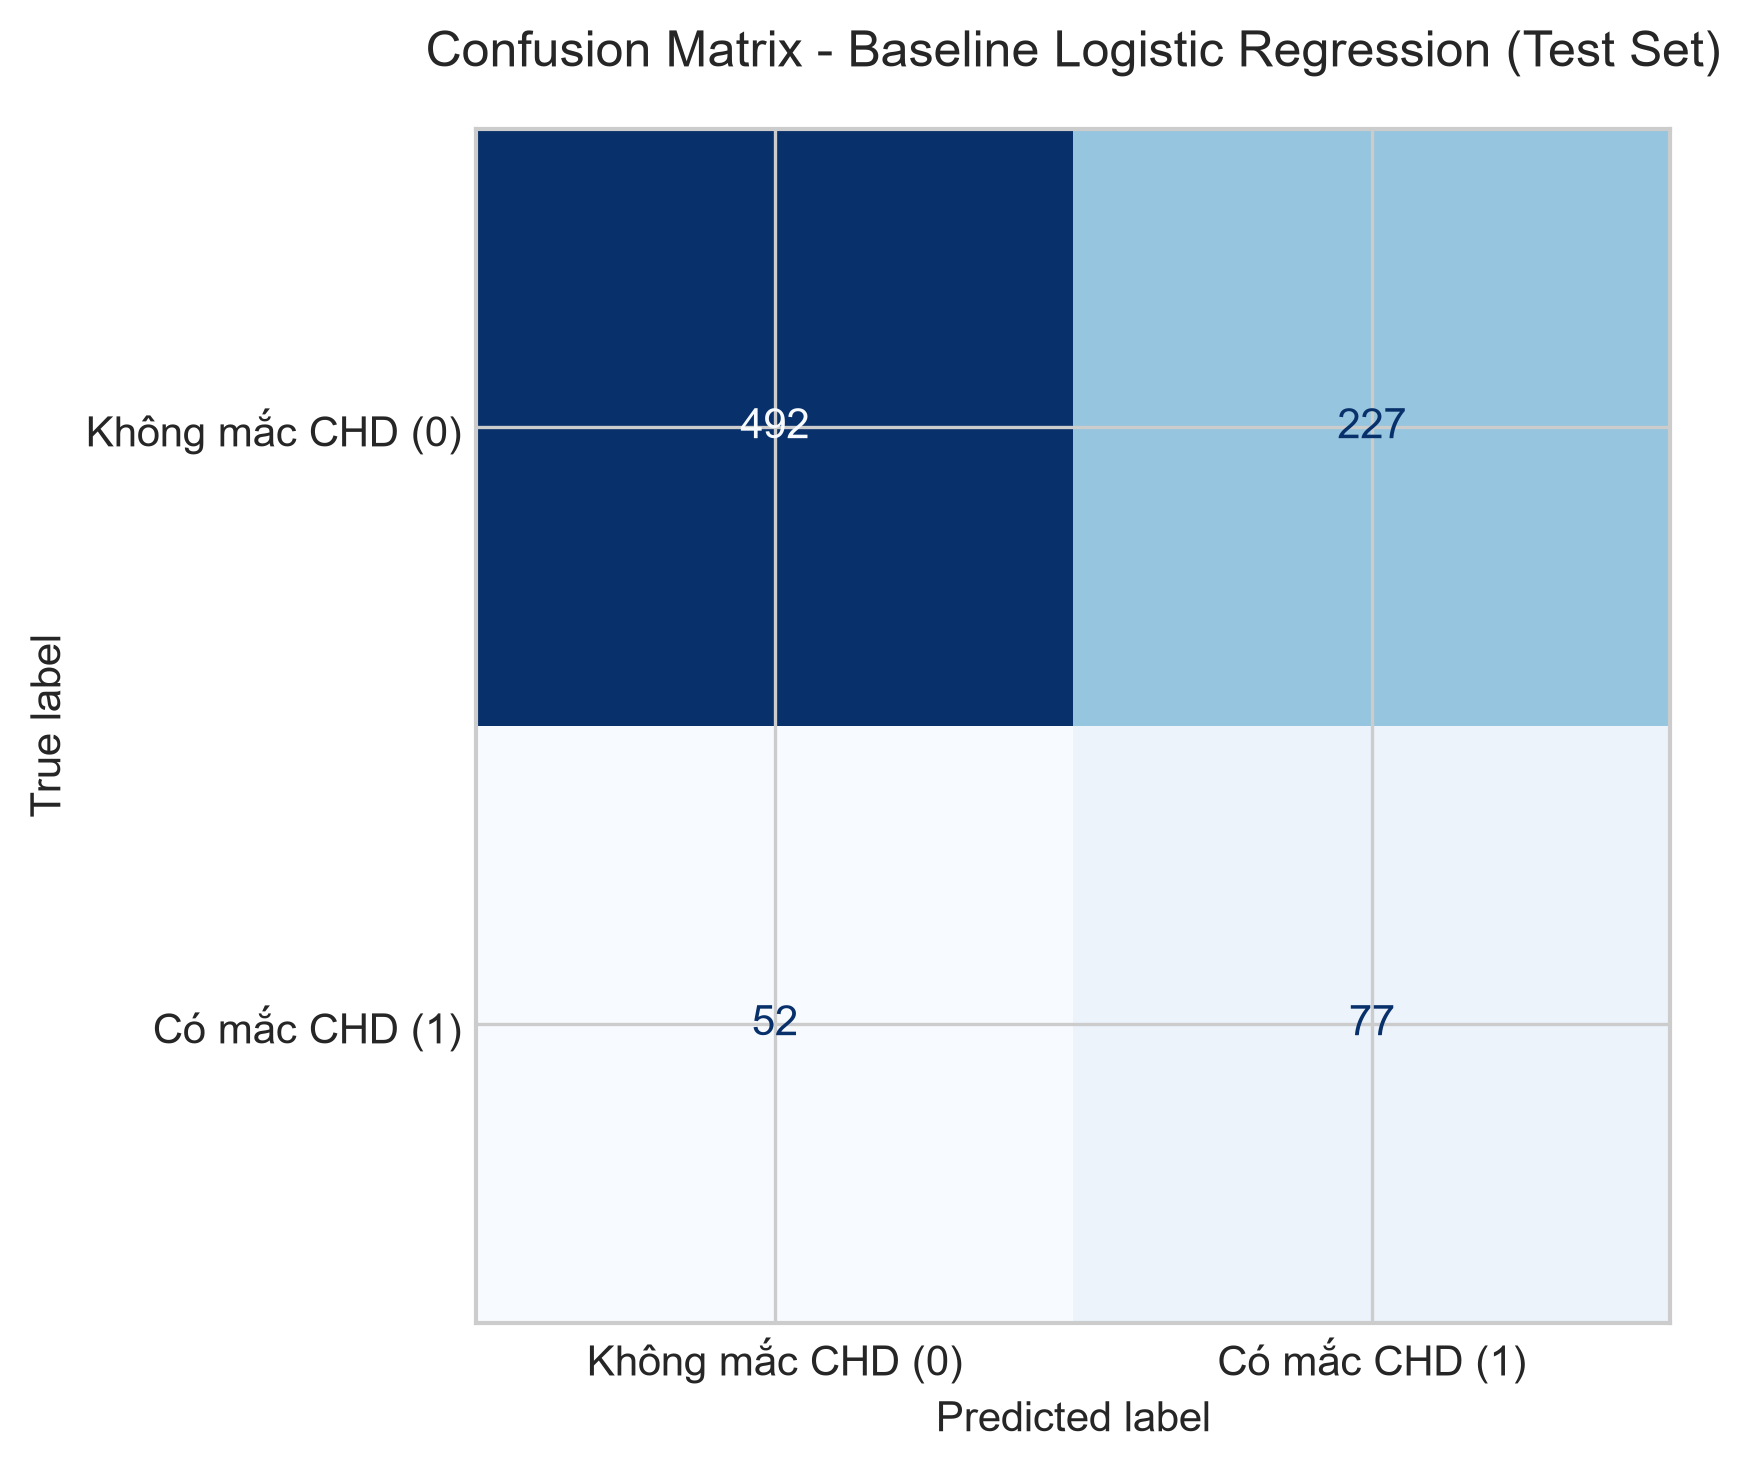

: 

: 

In [ ]:
# 6.1. Tính Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print(f'True Negative (TN):  {tn}')
print(f'False Positive (FP): {fp}')
print(f'False Negative (FN): {fn}')
print(f'True Positive (TP):  {tp}')

# 6.2. Vẽ Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5), dpi=300)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Không mắc CHD (0)', 'Có mắc CHD (1)'])
disp.plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
ax.set_title('Confusion Matrix - Baseline Logistic Regression (Test Set)', fontsize=12, pad=15)
plt.tight_layout()

# 6.3. Lưu hình ảnh
fig.savefig('../notebooks/figures/baseline_confusion_matrix.png', dpi=300, bbox_inches='tight')
print(f'Đã lưu Confusion Matrix tại: ../notebooks/figures/baseline_confusion_matrix.png')
plt.show()

## 7. ROC Curve (Đường Cong ROC)
Đánh giá khả năng phân biệt giữa 2 lớp qua các ngưỡng (threshold) khác nhau.
- Sử dụng xác suất lớp dương `y_prob = predict_proba()[:, 1]`
- Hiển thị đường chéo tham chiếu (random classifier)
- Hiển thị giá trị AUC trong legend

Đã lưu ROC Curve tại: ../notebooks/figures/baseline_roc_curve.png


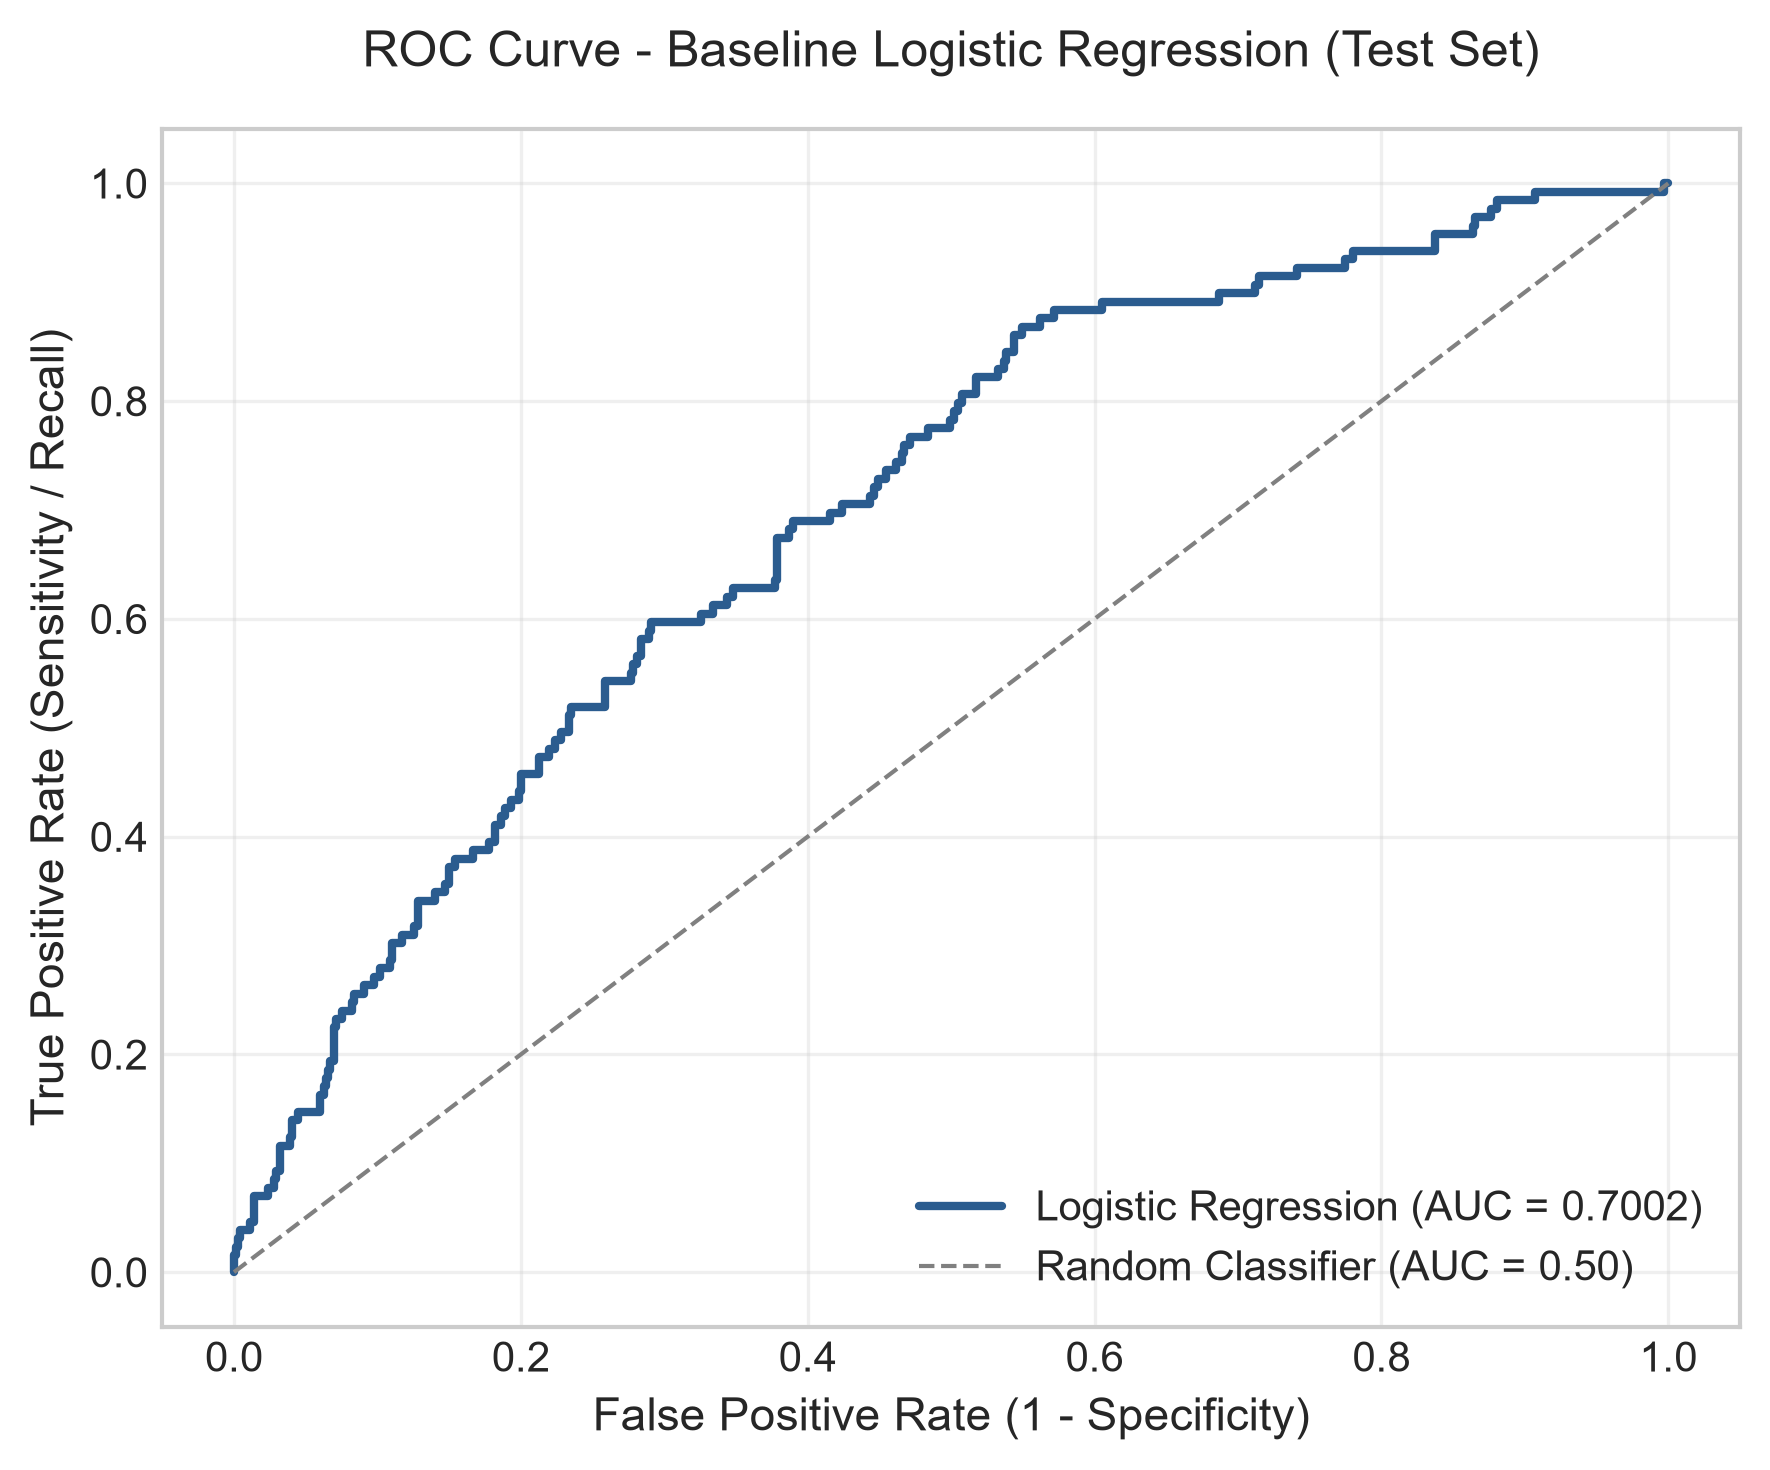

: 

: 

In [ ]:
# 7.1. Tính ROC Curve và AUC
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

# 7.2. Vẽ ROC Curve
fig, ax = plt.subplots(figsize=(6, 5), dpi=300)
ax.plot(fpr, tpr, color='#2b5c8f', lw=2, label=f'Logistic Regression (AUC = {auc_score:.4f})')
ax.plot([0, 1], [0, 1], '--', color='gray', lw=1, label='Random Classifier (AUC = 0.50)')
ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
ax.set_ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=11)
ax.set_title('ROC Curve - Baseline Logistic Regression (Test Set)', fontsize=12, pad=15)
ax.legend(loc='lower right', fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()

# 7.3. Lưu hình ảnh
fig.savefig('../notebooks/figures/baseline_roc_curve.png', dpi=300, bbox_inches='tight')
print(f'Đã lưu ROC Curve tại: ../notebooks/figures/baseline_roc_curve.png')
plt.show()

## 8. Nhận Xét & Kết Luận
**Tóm tắt hiệu suất Baseline Logistic Regression:**

1. **Cross-Validation (5-Fold Stratified trên Train):**
   - Các metric ổn định giữa các fold
   - Mean ROC-AUC, Recall, F1, Precision, Accuracy cho thấy mô hình có khả năng phân loại tốt

2. **Test Set Holdout:**
   - Kết quả Test set tương đồng với CV Mean → **Không overfitting**
   - ROC-AUC trên Test cho thấy khả năng phân biệt lớp tốt
   - Recall (Sensitivity) quan trọng trong y tế: phát hiện đúng bệnh nhân có nguy cơ

3. **Confusion Matrix:**
   - FN (False Negative) cần được giảm thiểu vì chi phí bỏ sót bệnh nhân cao
   - class_weight='balanced' giúp cải thiện Recall cho lớp thiểu số

4. **ROC Curve:**
   - AUC > 0.7 cho thấy mô hình có giá trị phân loại
   - Đường cong nằm rõ rệt trên đường chéo ngẫu nhiên

**Kết luận:** Baseline Logistic Regression đáp ứng yêu cầu Milestone 1, sẵn sàng làm điểm mốc so sánh cho các mô hình nâng cao (TV3, TV4).